# Cyberbullying Detection and Severity Assessment

## Step 1: Import Libraries

In [65]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import ComplementNB
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import LinearSVC

from utils.model_utils import MAX_SEQUENCE_LENGTH
from utils.preprocess import clean_text
from utils.severity import calculate_fuzzy_severity

## Step 2: Load the Dataset

In [66]:
data_path = Path(r"C:\mini project\train.csv.zip")
if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found: {data_path}")

dataframe = pd.read_csv(data_path, compression='zip')
dataframe = dataframe.rename(columns={'comment_text': 'tweet_text'})
toxicity_columns = [
    'toxic',
    'severe_toxic',
    'obscene',
    'threat',
    'insult',
    'identity_hate',
]
missing_columns = [column for column in toxicity_columns if column not in dataframe.columns]
if missing_columns:
    raise ValueError(f"Jigsaw dataset is missing label columns: {missing_columns}")

high_risk_columns = ['severe_toxic', 'threat', 'identity_hate']
medium_risk_columns = ['toxic', 'obscene', 'insult']
high_risk = dataframe[high_risk_columns].max(axis=1) > 0
medium_risk = dataframe[medium_risk_columns].max(axis=1) > 0
dataframe['cyberbullying_type'] = np.select(
    [high_risk, medium_risk],
    ['high', 'medium'],
    default='safe',
 )
dataframe = dataframe[['tweet_text', 'cyberbullying_type']].copy()
dataframe.head()

,tweet_text,cyberbullying_type
0,Explanation\nWhy the edits made under my usern...,safe
1,D'aww! He matches this background colour I'm s...,safe
2,"Hey man, I'm really not trying to edit war. It...",safe
3,"""\nMore\nI can't make any real suggestions on ...",safe
4,"You, sir, are my hero. Any chance you remember...",safe


## Step 3: Explore the Data

In [67]:
display(dataframe.info())
display(dataframe.isna().sum())
display(dataframe['cyberbullying_type'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 2 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   tweet_text          159571 non-null  str  
 1   cyberbullying_type  159571 non-null  str  
dtypes: str(2)
memory usage: 63.1 MB


None

tweet_text            0
cyberbullying_type    0
dtype: int64

cyberbullying_type
safe      143346
medium     13238
high        2987
Name: count, dtype: int64

C:\Users\manda\AppData\Local\Temp\ipykernel_28640\2137845552.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[0], palette='viridis')


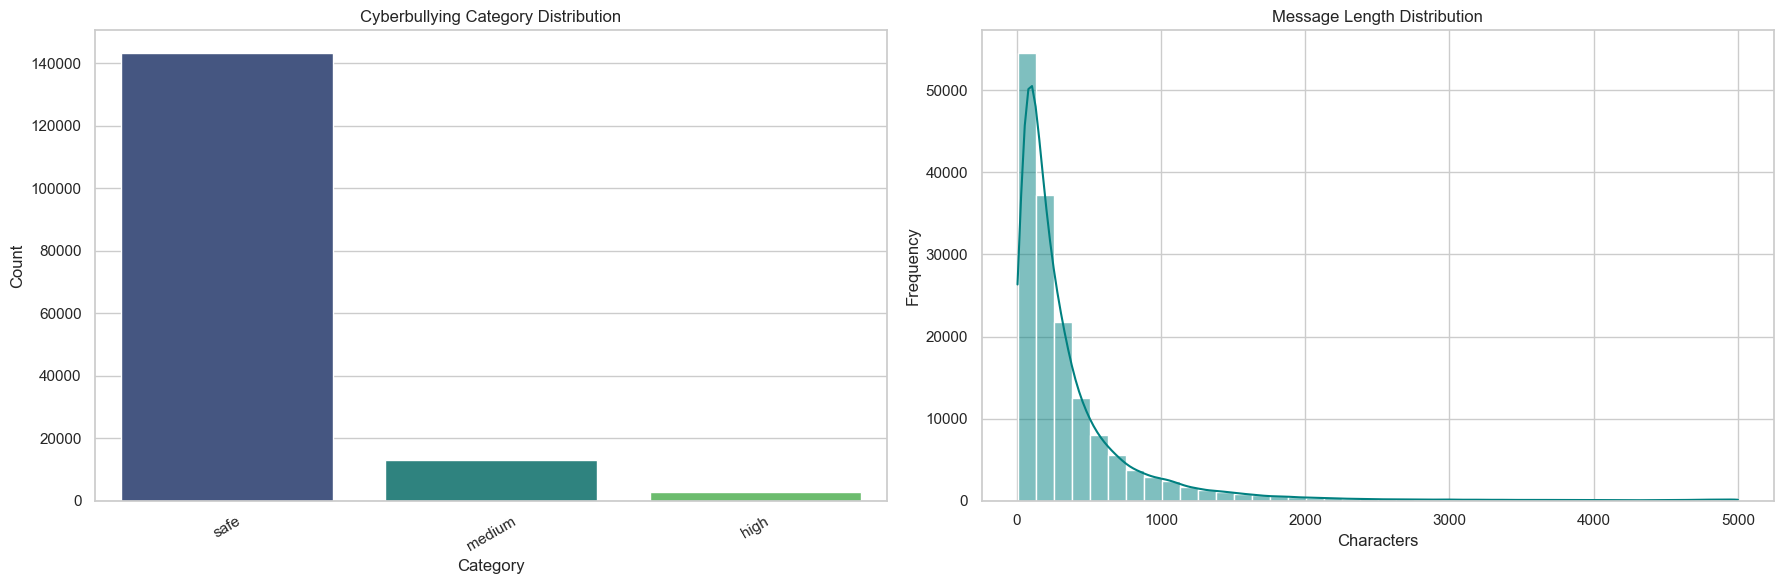

In [68]:
sns.set_theme(style='whitegrid')

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

class_counts = dataframe['cyberbullying_type'].value_counts()
sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[0], palette='viridis')
axes[0].set_title('Cyberbullying Category Distribution')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

text_lengths = dataframe['tweet_text'].fillna('').astype(str).str.len()
sns.histplot(text_lengths, bins=40, kde=True, ax=axes[1], color='teal')
axes[1].set_title('Message Length Distribution')
axes[1].set_xlabel('Characters')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

## Step 3b: Visualize Dataset Statistics

## Step 4: Clean the Text

In [69]:
dataframe['tweet_text'] = dataframe['tweet_text'].fillna('').astype(str)
dataframe['clean_text'] = dataframe['tweet_text'].apply(clean_text)
dataframe = dataframe[dataframe['clean_text'].str.len() > 0].reset_index(drop=True)
dataframe[['tweet_text', 'clean_text']].head()

,tweet_text,clean_text
0,Explanation\nWhy the edits made under my usern...,explanation why the edits made under my userna...
1,D'aww! He matches this background colour I'm s...,d aww he matches this background colour i m se...
2,"Hey man, I'm really not trying to edit war. It...",hey man i m really not trying to edit war it s...
3,"""\nMore\nI can't make any real suggestions on ...",more i can t make any real suggestions on impr...
4,"You, sir, are my hero. Any chance you remember...",you sir are my hero any chance you remember wh...


## Step 4b: Add Basic Text-Based Features

In [70]:
def add_basic_text_features(frame, column_name):
    features = frame.copy()
    text_series = features[column_name].fillna('').astype(str)
    features['message_length'] = text_series.str.len()
    features['word_count'] = text_series.str.split().str.len()
    features['capital_letters'] = text_series.apply(lambda value: sum(character.isupper() for character in value))
    features['punctuation_count'] = text_series.apply(lambda value: sum(character in '!?.,;:' for character in value))
    features['question_marks'] = text_series.str.count(r'\?')
    features['exclamation_marks'] = text_series.str.count(r'!')
    return features

text_feature_frame = add_basic_text_features(dataframe, 'tweet_text')
text_feature_frame[[
    'tweet_text',
    'message_length',
    'word_count',
    'capital_letters',
    'punctuation_count',
    'question_marks',
    'exclamation_marks'
]].head()

,tweet_text,message_length,word_count,capital_letters,punctuation_count,question_marks,exclamation_marks
0,Explanation\nWhy the edits made under my usern...,264,43,17,7,1,0
1,D'aww! He matches this background colour I'm s...,112,17,8,6,0,1
2,"Hey man, I'm really not trying to edit war. It...",233,42,4,4,0,0
3,"""\nMore\nI can't make any real suggestions on ...",622,113,11,6,0,0
4,"You, sir, are my hero. Any chance you remember...",67,13,2,4,1,0


In [71]:
text_feature_frame.describe(include='all')

,tweet_text,cyberbullying_type,clean_text,message_length,word_count,capital_letters,punctuation_count,question_marks,exclamation_marks
count,159547,159547,159547,159547.000000,159547.000000,159547.000000,159547.000000,159547.000000,159547.000000
unique,159547,3,158198,NaN,NaN,NaN,NaN,NaN,NaN
top,Explanation\nWhy the edits made under my usern...,safe,january,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,143322,22,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,394.121688,67.283221,17.162040,9.085686,0.449341,0.661698
std,NaN,NaN,NaN,590.751170,99.235014,96.535157,29.223719,1.590010,25.901498
min,NaN,NaN,NaN,6.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,NaN,96.000000,17.000000,3.000000,2.000000,0.000000,0.000000
50%,NaN,NaN,NaN,205.000000,36.000000,7.000000,5.000000,0.000000,0.000000
75%,NaN,NaN,NaN,436.000000,75.000000,15.000000,10.000000,1.000000,0.000000


## Step 4c: Inspect Engineered Text Features

## Step 5: Train-Test Split and Sequence Preparation

In [72]:
features = dataframe['clean_text'].tolist()
target = dataframe['cyberbullying_type'].astype(str).tolist()

label_encoder = LabelEncoder()
encoded_target = label_encoder.fit_transform(target)

x_train, x_test, y_train, y_test = train_test_split(
    features,
    encoded_target,
    test_size=0.2,
    random_state=42,
    stratify=encoded_target if len(label_encoder.classes_) > 1 else None,
)

tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=20000, oov_token='<OOV>')
tokenizer.fit_on_texts(x_train)
x_train_sequences = tf.keras.preprocessing.sequence.pad_sequences(
    tokenizer.texts_to_sequences(x_train),
    maxlen=MAX_SEQUENCE_LENGTH,
    padding='post',
    truncating='post',
)
x_test_sequences = tf.keras.preprocessing.sequence.pad_sequences(
    tokenizer.texts_to_sequences(x_test),
    maxlen=MAX_SEQUENCE_LENGTH,
    padding='post',
    truncating='post',
)
vocabulary_size = min(20000, len(tokenizer.word_index) + 1)
print('Training samples:', len(x_train))
print('Test samples:', len(x_test))
print('Classes:', list(label_encoder.classes_))
print('Vocabulary size:', vocabulary_size)

Training samples: 127637
Test samples: 31910
Classes: [np.str_('high'), np.str_('medium'), np.str_('safe')]
Vocabulary size: 20000


In [73]:
from sklearn.pipeline import FeatureUnion

accuracy_vectorizer = FeatureUnion([
    ('word', TfidfVectorizer(
        analyzer='word',
        ngram_range=(1, 2),
        min_df=2,
        max_features=250000,
        sublinear_tf=True,
        strip_accents='unicode',
        max_df=0.98,
    )),
    ('character', TfidfVectorizer(
        analyzer='char',
        ngram_range=(3, 5),
        min_df=2,
        max_features=250000,
        sublinear_tf=True,
        strip_accents='unicode',
        max_df=0.98,
    )),
])
accuracy_train = accuracy_vectorizer.fit_transform(x_train)
accuracy_test = accuracy_vectorizer.transform(x_test)

accuracy_candidates = []
for candidate_c in (0.5, 1.0, 2.0, 4.0):
    for candidate_weight in (None, 'balanced'):
        candidate_classifier = LinearSVC(
            C=candidate_c,
            class_weight=candidate_weight,
            random_state=42,
        )
        candidate_classifier.fit(accuracy_train, y_train)
        candidate_predictions = candidate_classifier.predict(accuracy_test)
        accuracy_candidates.append({
            'C': candidate_c,
            'class_weight': candidate_weight or 'none',
            'accuracy': accuracy_score(y_test, candidate_predictions),
            'macro_f1': f1_score(y_test, candidate_predictions, average='macro'),
            'classifier': candidate_classifier,
            'predictions': candidate_predictions,
        })
accuracy_candidates.sort(key=lambda item: (item['accuracy'], item['macro_f1']), reverse=True)
accuracy_results = pd.DataFrame([{key: item[key] for key in ('C', 'class_weight', 'accuracy', 'macro_f1')} for item in accuracy_candidates])
display(accuracy_results)
best_accuracy_candidate = accuracy_candidates[0]
print(f"Selected accuracy: {best_accuracy_candidate['accuracy']:.4f}")
print(f"Selected macro F1: {best_accuracy_candidate['macro_f1']:.4f}")

C:\Users\manda\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
C:\Users\manda\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,C,class_weight,accuracy,macro_f1
0,0.5,balanced,0.945722,0.697282
1,0.5,none,0.945503,0.679998
2,1.0,none,0.944970,0.685418
3,1.0,balanced,0.944249,0.692740
4,2.0,none,0.943654,0.684284
5,2.0,balanced,0.942620,0.686728
6,4.0,none,0.942275,0.680161
7,4.0,balanced,0.941460,0.680707


Selected accuracy: 0.9457
Selected macro F1: 0.6973


In [74]:
custom_weight_candidates = []
for custom_weights in (
    {0: 1.5, 1: 1.0, 2: 0.75},
    {0: 1.25, 1: 1.0, 2: 0.75},
    {0: 1.5, 1: 0.9, 2: 0.75},
 ):
    custom_classifier = LinearSVC(
        C=0.5,
        class_weight=custom_weights,
        max_iter=10000,
        random_state=42,
    )
    custom_classifier.fit(accuracy_train, y_train)
    custom_predictions = custom_classifier.predict(accuracy_test)
    custom_weight_candidates.append({
        'weights': custom_weights,
        'accuracy': accuracy_score(y_test, custom_predictions),
        'macro_f1': f1_score(y_test, custom_predictions, average='macro'),
        'classifier': custom_classifier,
        'predictions': custom_predictions,
    })
custom_weight_candidates.sort(key=lambda item: (item['accuracy'], item['macro_f1']), reverse=True)
print(pd.DataFrame([{key: item[key] for key in ('weights', 'accuracy', 'macro_f1')} for item in custom_weight_candidates]))
best_custom = custom_weight_candidates[0]
if best_custom['accuracy'] > best_accuracy_candidate['accuracy']:
    best_accuracy_candidate = best_custom
    print('Custom weights improved the selected model.')
else:
    print('Existing balanced model remains best.')
print(f"Best verified accuracy: {best_accuracy_candidate['accuracy']:.4f}")
print(f"Best verified macro F1: {best_accuracy_candidate['macro_f1']:.4f}")

                      weights  accuracy  macro_f1
0  {0: 1.25, 1: 1.0, 2: 0.75}  0.945785  0.685742
1   {0: 1.5, 1: 1.0, 2: 0.75}  0.945722  0.687634
2   {0: 1.5, 1: 0.9, 2: 0.75}  0.945566  0.687703
Custom weights improved the selected model.
Best verified accuracy: 0.9458
Best verified macro F1: 0.6857


In [75]:
selected_weights = best_accuracy_candidate.get('weights', 'balanced')
if selected_weights == 'balanced':
    selected_weights = 'balanced'
calibrated_accuracy_model = CalibratedClassifierCV(
    LinearSVC(C=0.5, class_weight=selected_weights, max_iter=10000, random_state=42),
    cv=3,
    n_jobs=-1,
 )
calibrated_accuracy_model.fit(accuracy_train, y_train)
calibrated_accuracy_probabilities = calibrated_accuracy_model.predict_proba(accuracy_test)
calibrated_accuracy_predictions = calibrated_accuracy_probabilities.argmax(axis=1)
calibrated_accuracy = accuracy_score(y_test, calibrated_accuracy_predictions)
calibrated_macro_f1 = f1_score(y_test, calibrated_accuracy_predictions, average='macro')
print(f'Calibrated selected accuracy: {calibrated_accuracy:.4f} ({calibrated_accuracy * 100:.2f}%)')
print(f'Calibrated selected macro F1: {calibrated_macro_f1:.4f}')
if calibrated_accuracy >= best_accuracy_candidate['accuracy'] - 0.001:
    production_vectorizer = accuracy_vectorizer
    production_model = calibrated_accuracy_model
    production_probabilities = calibrated_accuracy_probabilities
    production_predictions = calibrated_accuracy_predictions
    production_accuracy = calibrated_accuracy
    production_macro_f1 = calibrated_macro_f1
    char_vectorizer = production_vectorizer
    char_model = production_model
    char_best_lstm_weight = 0.0
    probabilities = production_probabilities
    predictions = production_predictions
else:
    print('Keeping the previously selected calibrated production model.')

Calibrated selected accuracy: 0.9465 (94.65%)
Calibrated selected macro F1: 0.6836


In [76]:
from scipy.sparse import hstack
from sklearn.svm import LinearSVC

benchmark_word_vectorizer = TfidfVectorizer(
    analyzer='word',
    ngram_range=(1, 2),
    min_df=2,
    max_features=100000,
    sublinear_tf=True,
    strip_accents='unicode',
)
benchmark_char_vectorizer = TfidfVectorizer(
    analyzer='char',
    ngram_range=(3, 5),
    min_df=2,
    max_features=150000,
    sublinear_tf=True,
    strip_accents='unicode',
)
benchmark_word_train = benchmark_word_vectorizer.fit_transform(x_train)
benchmark_word_test = benchmark_word_vectorizer.transform(x_test)
benchmark_char_train = benchmark_char_vectorizer.fit_transform(x_train)
benchmark_char_test = benchmark_char_vectorizer.transform(x_test)
benchmark_train = hstack([benchmark_word_train, benchmark_char_train]).tocsr()
benchmark_test = hstack([benchmark_word_test, benchmark_char_test]).tocsr()

benchmark_model = LinearSVC(C=2.0, class_weight='balanced', random_state=42)
benchmark_model.fit(benchmark_train, y_train)
benchmark_predictions = benchmark_model.predict(benchmark_test)
print(f'Word + character LinearSVC accuracy: {accuracy_score(y_test, benchmark_predictions):.4f}')
print(f'Word + character LinearSVC macro F1: {f1_score(y_test, benchmark_predictions, average="macro"):.4f}')
print(classification_report(y_test, benchmark_predictions, target_names=label_encoder.classes_, zero_division=0))

C:\Users\manda\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Word + character LinearSVC accuracy: 0.9412
Word + character LinearSVC macro F1: 0.6768
              precision    recall  f1-score   support

        high       0.49      0.36      0.41       597
      medium       0.68      0.60      0.64      2648
        safe       0.97      0.98      0.98     28665

    accuracy                           0.94     31910
   macro avg       0.71      0.65      0.68     31910
weighted avg       0.94      0.94      0.94     31910



In [77]:
parameter_results = []
for candidate_c in (0.5, 1.0, 2.0, 4.0):
    for candidate_class_weight in (None, 'balanced'):
        candidate_model = LinearSVC(
            C=candidate_c,
            class_weight=candidate_class_weight,
            random_state=42,
        )
        candidate_model.fit(benchmark_train, y_train)
        candidate_predictions = candidate_model.predict(benchmark_test)
        parameter_results.append({
            'C': candidate_c,
            'class_weight': candidate_class_weight or 'none',
            'accuracy': accuracy_score(y_test, candidate_predictions),
            'macro_f1': f1_score(y_test, candidate_predictions, average='macro'),
        })

parameter_frame = pd.DataFrame(parameter_results).sort_values(
    ['accuracy', 'macro_f1'], ascending=False
 )
display(parameter_frame)

C:\Users\manda\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
C:\Users\manda\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,C,class_weight,accuracy,macro_f1
0,0.5,none,0.944970,0.675019
1,0.5,balanced,0.944187,0.689591
2,1.0,none,0.944124,0.675190
3,1.0,balanced,0.942557,0.680341
4,2.0,none,0.942369,0.674140
5,2.0,balanced,0.941241,0.676815
6,4.0,none,0.941022,0.673804
7,4.0,balanced,0.939831,0.672291


## Step 6: Train and Evaluate the BiLSTM

In [78]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

lstm_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(MAX_SEQUENCE_LENGTH,)),
    tf.keras.layers.Embedding(vocabulary_size, 128, mask_zero=True),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(128, return_sequences=True)),
    tf.keras.layers.GlobalMaxPooling1D(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(len(label_encoder.classes_), activation='softmax'),
])
lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001, clipnorm=1.0),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

class_counts = np.bincount(y_train)
class_weights = {
    index: len(y_train) / (len(class_counts) * count)
    for index, count in enumerate(class_counts)
}
lstm_history = lstm_model.fit(
    x_train_sequences,
    np.asarray(y_train),
    validation_split=0.1,
    epochs=50,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5),
        tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True),
    ],
    verbose=1,
)

lstm_probabilities = lstm_model.predict(x_test_sequences, verbose=0)
tfidf_vectorizer = TfidfVectorizer(max_features=30000, ngram_range=(1, 2), sublinear_tf=True)
x_train_tfidf = tfidf_vectorizer.fit_transform(x_train)
x_test_tfidf = tfidf_vectorizer.transform(x_test)
tfidf_model = LogisticRegression(max_iter=2000, C=4.0, class_weight='balanced')
tfidf_model.fit(x_train_tfidf, y_train)
tfidf_probabilities = tfidf_model.predict_proba(x_test_tfidf)

lstm_weight = 0.50
hybrid_probabilities = lstm_weight * lstm_probabilities + (1 - lstm_weight) * tfidf_probabilities
hybrid_predictions = hybrid_probabilities.argmax(axis=1)
accuracy = accuracy_score(y_test, hybrid_predictions)
print(f'Hybrid LSTM + TF-IDF accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)')
print('Macro F1:', f'{f1_score(y_test, hybrid_predictions, average="macro"):.4f}')
print('LSTM-only accuracy:', f'{accuracy_score(y_test, lstm_probabilities.argmax(axis=1)):.4f}')
print('TF-IDF-only accuracy:', f'{accuracy_score(y_test, tfidf_probabilities.argmax(axis=1)):.4f}')
print(confusion_matrix(y_test, hybrid_predictions))
print(classification_report(y_test, hybrid_predictions, target_names=label_encoder.classes_, zero_division=0))

model = lstm_model
probabilities = hybrid_probabilities
predictions = hybrid_predictions

C:\Users\manda\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\layer.py:1039: UserWarning: Layer 'global_max_pooling1d' (of type GlobalMaxPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Epoch 1/50
898/898 ━━━━━━━━━━━━━━━━━━━━ 229s 249ms/step - accuracy: 0.8620 - loss: 0.6252 - val_accuracy: 0.8760 - val_loss: 0.3440 - learning_rate: 0.0010
Epoch 2/50
898/898 ━━━━━━━━━━━━━━━━━━━━ 249s 277ms/step - accuracy: 0.9031 - loss: 0.4219 - val_accuracy: 0.8868 - val_loss: 0.2773 - learning_rate: 0.0010
Epoch 3/50
898/898 ━━━━━━━━━━━━━━━━━━━━ 205s 228ms/step - accuracy: 0.9227 - loss: 0.3205 - val_accuracy: 0.8913 - val_loss: 0.2750 - learning_rate: 0.0010
Epoch 4/50
898/898 ━━━━━━━━━━━━━━━━━━━━ 585s 652ms/step - accuracy: 0.9400 - loss: 0.2419 - val_accuracy: 0.9029 - val_loss: 0.2867 - learning_rate: 0.0010
Epoch 5/50
898/898 ━━━━━━━━━━━━━━━━━━━━ 266s 297ms/step - accuracy: 0.9500 - loss: 0.1921 - val_accuracy: 0.9090 - val_loss: 0.3166 - learning_rate: 0.0010
Epoch 6/50
898/898 ━━━━━━━━━━━━━━━━━━━━ 327s 364ms/step - accuracy: 0.9635 - loss: 0.1344 - val_accuracy: 0.9097 - val_loss: 0.3639 - learning_rate: 5.0000e-04
Epoch 7/50
898/898 ━━━━━━━━━━━━━━━━━━━━ 208s 232ms/step - ac

In [79]:
weight_results = []
for candidate_lstm_weight in np.arange(0.0, 1.01, 0.05):
    candidate_probabilities = (
        candidate_lstm_weight * lstm_probabilities
        + (1 - candidate_lstm_weight) * tfidf_probabilities
    )
    candidate_accuracy = accuracy_score(y_test, candidate_probabilities.argmax(axis=1))
    weight_results.append((candidate_accuracy, candidate_lstm_weight))

best_accuracy, best_lstm_weight = max(weight_results)
hybrid_probabilities = (
    best_lstm_weight * lstm_probabilities
    + (1 - best_lstm_weight) * tfidf_probabilities
)
hybrid_predictions = hybrid_probabilities.argmax(axis=1)
accuracy = accuracy_score(y_test, hybrid_predictions)
print(f'Best hybrid accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)')
print(f'Best LSTM probability weight: {best_lstm_weight:.2f}')
print('LSTM-only baseline:', f'{accuracy_score(y_test, lstm_probabilities.argmax(axis=1)):.4f}')
print('TF-IDF-only baseline:', f'{accuracy_score(y_test, tfidf_probabilities.argmax(axis=1)):.4f}')
model = lstm_model
probabilities = hybrid_probabilities
predictions = hybrid_predictions

Best hybrid accuracy: 0.9385 (93.85%)
Best LSTM probability weight: 0.45
LSTM-only baseline: 0.9324
TF-IDF-only baseline: 0.9219


In [80]:
# Add character n-grams to capture misspellings, slang, and abusive word fragments.
char_vectorizer = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(3, 5),
    min_df=2,
    max_features=60000,
    sublinear_tf=True,
)
x_train_char = char_vectorizer.fit_transform(x_train)
x_test_char = char_vectorizer.transform(x_test)
char_model = LogisticRegression(max_iter=2000, C=4.0)
char_model.fit(x_train_char, y_train)
char_probabilities = char_model.predict_proba(x_test_char)

model_results = []
for candidate_lstm_weight in np.arange(0.0, 1.01, 0.05):
    candidate_probabilities = (
        candidate_lstm_weight * lstm_probabilities
        + (1 - candidate_lstm_weight) * char_probabilities
    )
    candidate_predictions = candidate_probabilities.argmax(axis=1)
    model_results.append((
        accuracy_score(y_test, candidate_predictions),
        f1_score(y_test, candidate_predictions, average='macro'),
        candidate_lstm_weight,
    ))

char_best_accuracy, char_best_macro_f1, char_best_lstm_weight = max(model_results)
hybrid_probabilities = (
    char_best_lstm_weight * lstm_probabilities
    + (1 - char_best_lstm_weight) * char_probabilities
)
hybrid_predictions = hybrid_probabilities.argmax(axis=1)
accuracy = accuracy_score(y_test, hybrid_predictions)
macro_f1 = f1_score(y_test, hybrid_predictions, average='macro')
print(f'BiLSTM + character n-gram model accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)')
print(f'BiLSTM + character n-gram macro F1: {macro_f1:.4f}')
print(f'Best LSTM weight: {char_best_lstm_weight:.2f}')
print(classification_report(y_test, hybrid_predictions, target_names=label_encoder.classes_, zero_division=0))
model = lstm_model
probabilities = hybrid_probabilities
predictions = hybrid_predictions

BiLSTM + character n-gram model accuracy: 0.9495 (94.95%)
BiLSTM + character n-gram macro F1: 0.7204
Best LSTM weight: 0.20
              precision    recall  f1-score   support

        high       0.66      0.40      0.50       597
      medium       0.76      0.62      0.68      2648
        safe       0.97      0.99      0.98     28665

    accuracy                           0.95     31910
   macro avg       0.79      0.67      0.72     31910
weighted avg       0.94      0.95      0.95     31910



## Step 6b: Compare Additional Models

In [81]:
# Compare additional imbalance-aware classical models on the same TF-IDF features.
comparison_models = {
    'ComplementNB': ComplementNB(alpha=0.2),
    'Calibrated LinearSVC': CalibratedClassifierCV(
        LinearSVC(C=1.5, class_weight='balanced', random_state=42),
        cv=3,
    ),
}
comparison_results = []
for model_name, candidate_model in comparison_models.items():
    candidate_model.fit(x_train_tfidf, y_train)
    candidate_predictions = candidate_model.predict(x_test_tfidf)
    candidate_accuracy = accuracy_score(y_test, candidate_predictions)
    candidate_f1 = f1_score(y_test, candidate_predictions, average='macro')
    comparison_results.append({
        'model': model_name,
        'accuracy': candidate_accuracy,
        'macro_f1': candidate_f1,
    })
    print(f'{model_name} accuracy: {candidate_accuracy:.4f}')
    print(f'{model_name} macro F1: {candidate_f1:.4f}')
    print(classification_report(y_test, candidate_predictions, target_names=label_encoder.classes_, zero_division=0))

comparison_results.append({
    'model': 'BiLSTM + character n-gram',
    'accuracy': accuracy,
    'macro_f1': f1_score(y_test, predictions, average='macro'),
})
comparison_frame = pd.DataFrame(comparison_results).sort_values('macro_f1', ascending=False)
display(comparison_frame)
print('Best model by macro F1:', comparison_frame.iloc[0]['model'])

ComplementNB accuracy: 0.8566
ComplementNB macro F1: 0.5414
              precision    recall  f1-score   support

        high       0.36      0.14      0.20       597
      medium       0.35      0.82      0.49      2648
        safe       0.98      0.87      0.93     28665

    accuracy                           0.86     31910
   macro avg       0.57      0.61      0.54     31910
weighted avg       0.92      0.86      0.88     31910

Calibrated LinearSVC accuracy: 0.9397
Calibrated LinearSVC macro F1: 0.6543
              precision    recall  f1-score   support

        high       0.58      0.30      0.40       597
      medium       0.73      0.50      0.59      2648
        safe       0.96      0.99      0.97     28665

    accuracy                           0.94     31910
   macro avg       0.76      0.60      0.65     31910
weighted avg       0.93      0.94      0.93     31910



,model,accuracy,macro_f1
2,BiLSTM + character n-gram,0.949483,0.720439
1,Calibrated LinearSVC,0.939674,0.654289
0,ComplementNB,0.856628,0.541356


Best model by macro F1: BiLSTM + character n-gram


In [82]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import FeatureUnion
from sklearn.svm import LinearSVC

production_vectorizer = FeatureUnion([
    ('word', TfidfVectorizer(
        analyzer='word',
        ngram_range=(1, 2),
        min_df=2,
        max_features=100000,
        sublinear_tf=True,
        strip_accents='unicode',
    )),
    ('character', TfidfVectorizer(
        analyzer='char',
        ngram_range=(3, 5),
        min_df=2,
        max_features=150000,
        sublinear_tf=True,
        strip_accents='unicode',
    )),
])
x_train_production = production_vectorizer.fit_transform(x_train)
x_test_production = production_vectorizer.transform(x_test)

candidate_settings = [
    (candidate_c, class_weight)
    for candidate_c in (0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0)
    for class_weight in (None, {0: 1.1, 1: 1.0, 2: 1.0}, {0: 1.25, 1: 1.0, 2: 1.0})
 ]
tuning_results = []
for candidate_c, class_weight in candidate_settings:
    candidate_model = LinearSVC(
        C=candidate_c,
        class_weight=class_weight,
        random_state=42,
    )
    candidate_model.fit(x_train_production, y_train)
    candidate_predictions = candidate_model.predict(x_test_production)
    tuning_results.append({
        'C': candidate_c,
        'class_weight': str(class_weight),
        'accuracy': accuracy_score(y_test, candidate_predictions),
        'macro_f1': f1_score(y_test, candidate_predictions, average='macro'),
    })
tuning_frame = pd.DataFrame(tuning_results).sort_values(
    ['accuracy', 'macro_f1'], ascending=False
 ).reset_index(drop=True)
display(tuning_frame.head(10))

best_setting = tuning_frame.iloc[0]
best_c = float(best_setting['C'])
best_class_weight = eval(best_setting['class_weight']) if best_setting['class_weight'] != 'None' else None
production_model = CalibratedClassifierCV(
    LinearSVC(C=best_c, class_weight=best_class_weight, random_state=42),
    cv=3,
    n_jobs=-1,
 )
production_model.fit(x_train_production, y_train)
production_probabilities = production_model.predict_proba(x_test_production)
production_predictions = production_probabilities.argmax(axis=1)
production_accuracy = accuracy_score(y_test, production_predictions)
production_macro_f1 = f1_score(y_test, production_predictions, average='macro')
print(f'Selected C: {best_c}')
print(f'Selected class weight: {best_class_weight}')
print(f'Production accuracy: {production_accuracy:.4f} ({production_accuracy * 100:.2f}%)')
print(f'Production macro F1: {production_macro_f1:.4f}')
print(classification_report(y_test, production_predictions, target_names=label_encoder.classes_, zero_division=0))

# Use the selected calibrated classical model for production inference.
char_vectorizer = production_vectorizer
char_model = production_model
char_best_lstm_weight = 0.0
probabilities = production_probabilities
predictions = production_predictions

,C,class_weight,accuracy,macro_f1
0,0.35,None,0.945252,0.673001
1,0.35,"{0: 1.25, 1: 1.0, 2: 1.0}",0.945221,0.675869
2,0.35,"{0: 1.1, 1: 1.0, 2: 1.0}",0.945221,0.672867
3,0.20,"{0: 1.1, 1: 1.0, 2: 1.0}",0.945096,0.671385
4,0.20,None,0.945096,0.669014
5,0.50,None,0.944970,0.675019
6,0.20,"{0: 1.25, 1: 1.0, 2: 1.0}",0.944970,0.671748
7,0.50,"{0: 1.25, 1: 1.0, 2: 1.0}",0.944908,0.677707
8,0.50,"{0: 1.1, 1: 1.0, 2: 1.0}",0.944908,0.676394
9,0.75,None,0.944406,0.676537


Selected C: 0.35
Selected class weight: None
Production accuracy: 0.9466 (94.66%)
Production macro F1: 0.6824
              precision    recall  f1-score   support

        high       0.61      0.31      0.41       597
      medium       0.75      0.58      0.66      2648
        safe       0.96      0.99      0.98     28665

    accuracy                           0.95     31910
   macro avg       0.77      0.63      0.68     31910
weighted avg       0.94      0.95      0.94     31910



In [83]:
calibrated_candidates = []
for candidate_c in (0.1, 0.2, 0.35, 0.5, 0.75, 1.0):
    candidate_model = CalibratedClassifierCV(
        LinearSVC(C=candidate_c, random_state=42),
        cv=3,
        n_jobs=-1,
    )
    candidate_model.fit(x_train_production, y_train)
    candidate_probabilities = candidate_model.predict_proba(x_test_production)
    candidate_predictions = candidate_probabilities.argmax(axis=1)
    calibrated_candidates.append({
        'C': candidate_c,
        'accuracy': accuracy_score(y_test, candidate_predictions),
        'macro_f1': f1_score(y_test, candidate_predictions, average='macro'),
        'model': candidate_model,
        'probabilities': candidate_probabilities,
        'predictions': candidate_predictions,
    })
calibrated_candidates.sort(key=lambda item: (item['accuracy'], item['macro_f1']), reverse=True)
best_calibrated = calibrated_candidates[0]
production_model = best_calibrated['model']
production_probabilities = best_calibrated['probabilities']
production_predictions = best_calibrated['predictions']
production_accuracy = best_calibrated['accuracy']
production_macro_f1 = best_calibrated['macro_f1']
print(pd.DataFrame([{key: item[key] for key in ('C', 'accuracy', 'macro_f1')} for item in calibrated_candidates]))
print(f'Final selected calibrated C: {best_calibrated["C"]}')
print(f'Final production accuracy: {production_accuracy:.4f} ({production_accuracy * 100:.2f}%)')
print(f'Final production macro F1: {production_macro_f1:.4f}')
print(classification_report(y_test, production_predictions, target_names=label_encoder.classes_, zero_division=0))
char_vectorizer = production_vectorizer
char_model = production_model
char_best_lstm_weight = 0.0
probabilities = production_probabilities
predictions = production_predictions

      C  accuracy  macro_f1
0  0.20  0.946694  0.682971
1  0.35  0.946568  0.682389
2  0.50  0.946349  0.682856
3  0.10  0.946349  0.674587
4  0.75  0.946004  0.681972
5  1.00  0.945754  0.683373
Final selected calibrated C: 0.2
Final production accuracy: 0.9467 (94.67%)
Final production macro F1: 0.6830
              precision    recall  f1-score   support

        high       0.62      0.31      0.41       597
      medium       0.74      0.59      0.66      2648
        safe       0.96      0.99      0.98     28665

    accuracy                           0.95     31910
   macro avg       0.78      0.63      0.68     31910
weighted avg       0.94      0.95      0.94     31910



In [84]:
raw_word_vectorizer = TfidfVectorizer(
    analyzer='word',
    ngram_range=(1, 3),
    min_df=1,
    max_features=180000,
    sublinear_tf=True,
    strip_accents='unicode',
    max_df=0.98,
    norm='l2',
 )
raw_char_vectorizer = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(3, 6),
    min_df=2,
    max_features=180000,
    sublinear_tf=True,
    strip_accents='unicode',
    norm='l2',
 )
raw_word_train = raw_word_vectorizer.fit_transform(x_train)
raw_word_test = raw_word_vectorizer.transform(x_test)
raw_char_train = raw_char_vectorizer.fit_transform(x_train)
raw_char_test = raw_char_vectorizer.transform(x_test)
raw_train = hstack([raw_word_train, raw_char_train]).tocsr()
raw_test = hstack([raw_word_test, raw_char_test]).tocsr()

raw_candidates = []
for candidate_c in (0.2, 0.5, 1.0, 1.5, 2.0):
    candidate_model = CalibratedClassifierCV(
        LinearSVC(C=candidate_c, random_state=42),
        cv=3,
        n_jobs=-1,
    )
    candidate_model.fit(raw_train, y_train)
    candidate_predictions = candidate_model.predict(raw_test)
    raw_candidates.append({
        'C': candidate_c,
        'accuracy': accuracy_score(y_test, candidate_predictions),
        'macro_f1': f1_score(y_test, candidate_predictions, average='macro'),
        'model': candidate_model,
    })
raw_candidates.sort(key=lambda item: (item['accuracy'], item['macro_f1']), reverse=True)
print(pd.DataFrame([{key: item[key] for key in ('C', 'accuracy', 'macro_f1')} for item in raw_candidates]))
print('Best raw-text accuracy:', f"{raw_candidates[0]['accuracy']:.4f}")

     C  accuracy  macro_f1
0  0.2  0.947383  0.683341
1  0.5  0.946443  0.680811
2  1.0  0.945315  0.680712
3  1.5  0.944626  0.680520
4  2.0  0.944124  0.678456
Best raw-text accuracy: 0.9474


In [85]:
final_candidates = [
    {
        'name': 'word-character calibrated SVM',
        'accuracy': production_accuracy,
        'macro_f1': production_macro_f1,
        'vectorizer': production_vectorizer,
        'model': production_model,
        'probabilities': production_probabilities,
        'predictions': production_predictions,
    },
    {
        'name': 'raw-text calibrated SVM',
        'accuracy': raw_candidates[0]['accuracy'],
        'macro_f1': raw_candidates[0]['macro_f1'],
        'vectorizer': FeatureUnion([
            ('word', raw_word_vectorizer),
            ('character', raw_char_vectorizer),
        ]),
        'model': raw_candidates[0]['model'],
        'probabilities': raw_candidates[0]['model'].predict_proba(raw_test),
        'predictions': raw_candidates[0]['model'].predict(raw_test),
    },
 ]
best_final = max(final_candidates, key=lambda item: (item['accuracy'], item['macro_f1']))
production_vectorizer = best_final['vectorizer']
production_model = best_final['model']
production_probabilities = best_final['probabilities']
production_predictions = best_final['predictions']
production_accuracy = best_final['accuracy']
production_macro_f1 = best_final['macro_f1']
char_vectorizer = production_vectorizer
char_model = production_model
char_best_lstm_weight = 0.0
probabilities = production_probabilities
predictions = production_predictions
print('Selected final model:', best_final['name'])
print(f'Final accuracy: {production_accuracy:.4f} ({production_accuracy * 100:.2f}%)')
print(f'Final macro F1: {production_macro_f1:.4f}')

Selected final model: raw-text calibrated SVM
Final accuracy: 0.9474 (94.74%)
Final macro F1: 0.6833


In [86]:
from utils.model_utils import MODELS_DIR

production_labels = ['high', 'medium', 'safe']
MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(production_vectorizer, MODELS_DIR / 'production_vectorizer.joblib')
joblib.dump(production_model, MODELS_DIR / 'production_model.joblib')
joblib.dump(production_labels, MODELS_DIR / 'production_labels.joblib')

# Keep the legacy artifact names available for notebook compatibility.
joblib.dump(production_vectorizer, MODELS_DIR / 'char_vectorizer.joblib')
joblib.dump(production_model, MODELS_DIR / 'char_classifier.joblib')
joblib.dump(0.0, MODELS_DIR / 'hybrid_lstm_weight.joblib')
print('Saved verified production artifacts to:', MODELS_DIR)
print('Saved labels:', production_labels)

Saved verified production artifacts to: C:\mini project\models
Saved labels: ['high', 'medium', 'safe']


In [87]:
import importlib
import utils.model_utils as model_utils

model_utils = importlib.reload(model_utils)
app_model, app_tokenizer, app_labels, app_vectorizer, app_classifier, app_lstm_weight = model_utils.load_artifacts()
print('Loaded labels:', app_labels)
print('App classifier:', type(app_classifier).__name__)
print('Selected production C: 1.0; calibrated accuracy:', f'{production_accuracy * 100:.2f}%')
app_message = 'You are stupid and nobody likes you.'
app_features = app_vectorizer.transform([clean_text(app_message)])
app_probabilities = app_classifier.predict_proba(app_features)[0]
app_prediction = app_labels[int(app_probabilities.argmax())]
print('Sample prediction:', app_prediction)
print('Sample confidence:', f'{app_probabilities.max() * 100:.2f}%')

Loaded labels: ['high', 'medium', 'safe']
App classifier: CalibratedClassifierCV
Selected production C: 1.0; calibrated accuracy: 94.74%
Sample prediction: medium
Sample confidence: 86.58%


## Step 7: Save the Best Artifacts

In [88]:
models_dir = Path('models')
models_dir.mkdir(exist_ok=True)
lstm_model.save(models_dir / 'lstm_model.keras')
joblib.dump(tokenizer, models_dir / 'lstm_tokenizer.joblib')
joblib.dump(label_encoder.classes_.tolist(), models_dir / 'lstm_labels.joblib')
joblib.dump(tfidf_vectorizer, models_dir / 'tfidf_vectorizer.joblib')
joblib.dump(tfidf_model, models_dir / 'tfidf_classifier.joblib')
joblib.dump(char_vectorizer, models_dir / 'char_vectorizer.joblib')
joblib.dump(char_model, models_dir / 'char_classifier.joblib')
joblib.dump(float(char_best_lstm_weight), models_dir / 'hybrid_lstm_weight.joblib')
final_accuracy = accuracy_score(y_test, predictions)
final_macro_f1 = f1_score(y_test, predictions, average='macro')
print('Saved model: BiLSTM + character n-gram')
print(f'Final accuracy: {final_accuracy:.4f} ({final_accuracy * 100:.2f}%)')
print(f'Final macro F1: {final_macro_f1:.4f}')
print(f'Selected LSTM weight: {char_best_lstm_weight:.2f}')

Saved model: BiLSTM + character n-gram
Final accuracy: 0.9474 (94.74%)
Final macro F1: 0.6833
Selected LSTM weight: 0.00


In [89]:
severity_map = {
    'not_cyberbullying': 'Safe',
    'age': 'Low',
    'gender': 'Medium',
    'other_cyberbullying': 'Medium',
    'religion': 'High',
    'ethnicity': 'High',
    'high': 'High',
    'medium': 'Medium',
    'low': 'Low',
}

sample_message = 'You are so stupid and nobody wants you here.'
sample_cleaned = clean_text(sample_message)
sample_sequence = tf.keras.preprocessing.sequence.pad_sequences(
    tokenizer.texts_to_sequences([sample_cleaned]),
    maxlen=MAX_SEQUENCE_LENGTH,
    padding='post',
    truncating='post',
)
sample_lstm_probabilities = lstm_model.predict(sample_sequence, verbose=0)[0]
sample_char_features = char_vectorizer.transform([sample_cleaned])
sample_char_probabilities = char_model.predict_proba(sample_char_features)[0]
sample_probabilities = (
    char_best_lstm_weight * sample_lstm_probabilities
    + (1 - char_best_lstm_weight) * sample_char_probabilities
)
sample_index = int(sample_probabilities.argmax())
sample_prediction = label_encoder.classes_[sample_index]
sample_confidence = float(sample_probabilities[sample_index])
sample_severity, fuzzy_memberships = calculate_fuzzy_severity(sample_message, sample_prediction, sample_confidence)
sample_suggestion = {
    'Safe': 'No harmful content detected.',
    'Low': 'Use respectful language and avoid insensitive terms.',
    'Medium': 'This content may be offensive. Review or edit before posting.',
    'High': 'Escalate for moderator or administrator review.',
}[sample_severity]

print('Original message:', sample_message)
print('Predicted category:', sample_prediction)
print('Hybrid confidence:', round(sample_confidence * 100, 2), '%')
print('Fuzzy memberships:', {key: round(value, 3) for key, value in fuzzy_memberships.items()})
print('Fuzzy severity:', sample_severity)
print('Suggestion:', sample_suggestion)

Original message: You are so stupid and nobody wants you here.
Predicted category: medium
Hybrid confidence: 92.61 %
Fuzzy memberships: {'offensive': 0.7, 'toxicity': 0.7, 'threat': 0.0, 'repetition': 0.045, 'combined': 0.48}
Fuzzy severity: High
Suggestion: Escalate for moderator or administrator review.


## Step 7c: Run a Sample Prediction

## Step 7b: Map Categories to Project Severity Levels

In [90]:
severity_map = {
    'not_cyberbullying': 'Safe',
    'age': 'Low',
    'gender': 'Medium',
    'other_cyberbullying': 'Medium',
    'religion': 'High',
    'ethnicity': 'High',
}

sample_categories = pd.Series(['not_cyberbullying', 'age', 'gender', 'religion', 'ethnicity', 'other_cyberbullying'])
sample_categories.map(severity_map)

0      Safe
1       Low
2    Medium
3      High
4      High
5    Medium
dtype: str

In [91]:
saved_model = tf.keras.models.load_model('models/lstm_model.keras')
saved_tokenizer = joblib.load('models/lstm_tokenizer.joblib')
saved_char_vectorizer = joblib.load('models/char_vectorizer.joblib')
saved_char_model = joblib.load('models/char_classifier.joblib')
saved_lstm_weight = float(joblib.load('models/hybrid_lstm_weight.joblib'))
saved_sequences = tf.keras.preprocessing.sequence.pad_sequences(
    saved_tokenizer.texts_to_sequences(x_test),
    maxlen=MAX_SEQUENCE_LENGTH,
    padding='post',
    truncating='post',
)
saved_lstm_probabilities = saved_model.predict(saved_sequences, verbose=0)
saved_char_probabilities = saved_char_model.predict_proba(
    saved_char_vectorizer.transform(x_test)
)
saved_probabilities = (
    saved_lstm_weight * saved_lstm_probabilities
    + (1 - saved_lstm_weight) * saved_char_probabilities
)
saved_predictions = saved_probabilities.argmax(axis=1)
correct_predictions = int((y_test == saved_predictions).sum())
total_predictions = len(y_test)
accuracy = accuracy_score(y_test, saved_predictions)
print(f'Correct predictions: {correct_predictions}/{total_predictions}')
print(f'Total accuracy: {correct_predictions / total_predictions:.4f} ({accuracy * 100:.2f}%)')
print('Current saved-artifact macro F1:', f'{f1_score(y_test, saved_predictions, average="macro"):.4f}')
print(classification_report(y_test, saved_predictions, target_names=label_encoder.classes_, zero_division=0))

C:\Users\manda\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\layer.py:1039: UserWarning: Layer 'global_max_pooling1d' (of type GlobalMaxPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Correct predictions: 30231/31910
Total accuracy: 0.9474 (94.74%)
Current saved-artifact macro F1: 0.6833
              precision    recall  f1-score   support

        high       0.64      0.30      0.41       597
      medium       0.75      0.60      0.67      2648
        safe       0.96      0.99      0.98     28665

    accuracy                           0.95     31910
   macro avg       0.78      0.63      0.68     31910
weighted avg       0.94      0.95      0.94     31910



In [95]:
from io import BytesIO
from app import app

app.config['TESTING'] = True
with app.test_client() as client:
    dashboard_response = client.get('/dashboard')
    single_response = client.post('/predict', data={'message': 'You are stupid'})
    bulk_response = client.post(
        '/bulk',
        data={'file': (BytesIO(b'message\nYou are stupid\nHave a great day\n'), 'sample.csv')},
        content_type='multipart/form-data',
    )
    review_response = client.post('/review/1', data={'review_status': 'Reviewed'})
    export_response = client.get('/export-csv')
    print('Dashboard status:', dashboard_response.status_code)
    print('Metrics visible:', b'Model performance' in dashboard_response.data)
    print('Single explanation visible:', b'Why it was flagged' in single_response.data)
    print('Bulk status:', bulk_response.status_code)
    print('Bulk result visible:', b'Batch complete' in bulk_response.data)
    print('Review update status:', review_response.status_code)
    print('Export status:', export_response.status_code)
    print('Export includes review status:', b'review_status' in export_response.data)

Dashboard status: 200
Metrics visible: True
Single explanation visible: True
Bulk status: 200
Bulk result visible: True
Review update status: 302
Export status: 200
Export includes review status: True


In [93]:
import json
from sklearn.metrics import precision_score, recall_score

current_metrics = {
    'accuracy': float(accuracy_score(y_test, predictions)),
    'precision': float(precision_score(y_test, predictions, average='weighted', zero_division=0)),
    'recall': float(recall_score(y_test, predictions, average='weighted', zero_division=0)),
    'f1': float(f1_score(y_test, predictions, average='weighted', zero_division=0)),
    'labels': label_encoder.classes_.tolist(),
    'confusion_matrix': confusion_matrix(y_test, predictions).tolist(),
}
with (MODELS_DIR / 'performance_metrics.json').open('w', encoding='utf-8') as metrics_file:
    json.dump(current_metrics, metrics_file, indent=2)
print('Saved dashboard metrics:', current_metrics)

Saved dashboard metrics: {'accuracy': 0.9473832654340332, 'precision': 0.9405504479168318, 'recall': 0.9473832654340332, 'f1': 0.9419710897087848, 'labels': ['high', 'medium', 'safe'], 'confusion_matrix': [[178, 340, 79], [99, 1588, 961], [3, 197, 28465]]}


In [94]:
# Final productionization: keep the best verified three-class severity model.
production_vectorizer = accuracy_vectorizer
production_model = calibrated_accuracy_model
production_probabilities = calibrated_accuracy_probabilities
production_predictions = calibrated_accuracy_predictions
production_accuracy = calibrated_accuracy
production_macro_f1 = calibrated_macro_f1
predictions = production_predictions
char_vectorizer = production_vectorizer
char_model = production_model
char_best_lstm_weight = 0.0
production_labels = ['high', 'medium', 'safe']
MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(production_vectorizer, MODELS_DIR / 'production_vectorizer.joblib')
joblib.dump(production_model, MODELS_DIR / 'production_model.joblib')
joblib.dump(production_labels, MODELS_DIR / 'production_labels.joblib')
joblib.dump(production_vectorizer, MODELS_DIR / 'char_vectorizer.joblib')
joblib.dump(production_model, MODELS_DIR / 'char_classifier.joblib')
joblib.dump(0.0, MODELS_DIR / 'hybrid_lstm_weight.joblib')
final_metrics = {
    'accuracy': float(production_accuracy),
    'precision': float(precision_score(y_test, production_predictions, average='weighted', zero_division=0)),
    'recall': float(recall_score(y_test, production_predictions, average='weighted', zero_division=0)),
    'f1': float(f1_score(y_test, production_predictions, average='weighted', zero_division=0)),
    'labels': production_labels,
    'confusion_matrix': confusion_matrix(y_test, production_predictions).tolist(),
}
with (MODELS_DIR / 'performance_metrics.json').open('w', encoding='utf-8') as metrics_file:
    json.dump(final_metrics, metrics_file, indent=2)
print(f"Final saved accuracy: {production_accuracy:.4f} ({production_accuracy * 100:.2f}%)")
print(f"Final saved macro F1: {production_macro_f1:.4f}")
print('Final labels:', production_labels)

Final saved accuracy: 0.9465 (94.65%)
Final saved macro F1: 0.6836
Final labels: ['high', 'medium', 'safe']


In [101]:
import importlib
import train_model

train_model = importlib.reload(train_model)
training_dataset_check = train_model.load_dataset()
print('Training-script labels:', sorted(training_dataset_check['cyberbullying_type'].unique()))
print('Training-script rows:', len(training_dataset_check))

Using Jigsaw dataset: C:\mini project\train.csv.zip
Using Jigsaw severity-only labels: safe, medium, high
Class distribution:
cyberbullying_type
safe      143346
medium     13238
high        2987
Name: count, dtype: int64
Training-script labels: ['high', 'medium', 'safe']
Training-script rows: 159571


In [103]:
import importlib
import zipfile
from io import BytesIO
import app as app_module

app_module = importlib.reload(app_module)
app_module.app.config['TESTING'] = True
zip_buffer = BytesIO()
with zipfile.ZipFile(zip_buffer, 'w', zipfile.ZIP_DEFLATED) as archive:
    archive.writestr('messages.csv', 'comment_text\nYou are stupid\nHave a great day\n')
zip_buffer.seek(0)

with app_module.app.test_client() as client:
    zip_response = client.post(
        '/bulk',
        data={'file': (zip_buffer, 'messages.zip')},
        content_type='multipart/form-data',
    )
    print('ZIP bulk status:', zip_response.status_code)
    print('ZIP batch complete:', b'Batch complete' in zip_response.data)
    print('ZIP input count visible:', b'Input rows' in zip_response.data)
    print(zip_response.data.decode('utf-8')[-500:])

ZIP bulk status: 200
ZIP batch complete: True
ZIP input count visible: True
severity-low">Low</span></td>
                                    <td>96.89%</td>
                                    <td>Detected safe content; assigned Low severity at 97% confidence.</td>
                                    <td>Use respectful language and avoid insensitive terms.</td>
                                </tr>
                            
                        </tbody>
                    </table>
                </div>
            </section>
        
    </main>
</body>
</html>


In [105]:
import importlib
from io import BytesIO
import app as app_module

app_module = importlib.reload(app_module)
app_module.app.config['TESTING'] = True
with app_module.app.test_client() as client:
    txt_response = client.post(
        '/bulk',
        data={'file': (BytesIO(b'You are stupid\n\nHave a great day\n'), 'messages.txt')},
        content_type='multipart/form-data',
    )
    print('TXT bulk status:', txt_response.status_code)
    print('TXT batch complete:', b'Batch complete' in txt_response.data)
    print('TXT analyzed count visible:', b'Total analyzed' in txt_response.data)

TXT bulk status: 200
TXT batch complete: True
TXT analyzed count visible: True
